# Figure S15E — random-sequence proteins from Tretyachenko *et al.*

Fraction of each sequence predicted disordered by metapredict V3 for the 22 random-sequence proteins that Tretyachenko *et al.* (2017) *Sci. Rep.* 7, 15449 expressed and characterised by CD spectroscopy: 7 folded (blue) and 15 disordered (red). Background shading marks the experimental class.

**How it is made.** Sequences from `data/synthetic_proteins/tretyachenko.fasta` in the shared data directory (headers `<ID>_ORD` or `<ID>_IDR` give the experimental class); fraction disordered = residues inside metapredict V3 IDRs / length. A sequence is called disordered if more than half of it lies in IDRs, and the MCC of those calls against the experimental classes is printed.

**Output:** `figures/figure_S15E.pdf`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import protfasta

from figtools import apply_style, require_metapredict_3_1, save_panel, shared_data_path
from synthetic_disorder import fraction_disordered

require_metapredict_3_1()
apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# a sequence counts as predicted disordered if > half its residues are in IDRs
CALL_THRESHOLD = 0.5
FOLDED_COLOR, DISORDERED_COLOR = 'blue', 'red'

D = protfasta.read_fasta(str(shared_data_path('synthetic_proteins', 'tretyachenko.fasta')))

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
ordered, ordered_names = [], []
disordered, disordered_names = [], []
for k in D:
    seq_id, exp_class = k.split('_')
    if exp_class == 'IDR':
        disordered.append(fraction_disordered(D[k]))
        disordered_names.append(seq_id)
    elif exp_class == 'ORD':
        ordered.append(fraction_disordered(D[k]))
        ordered_names.append(seq_id)
assert len(ordered) == 7 and len(disordered) == 15, 'expected 7 folded and 15 disordered sequences'


def calculate_mcc(TP, TN, FP, FN):
    """Matthews correlation coefficient from confusion-matrix counts."""
    a = (TP * TN) - (FP * FN)
    b = (TP + FP) * (TP + FN) * (TN + FP) * (TN + FN)
    return a / np.sqrt(b)


TP = sum(f > CALL_THRESHOLD for f in disordered)
FN = len(disordered) - TP
FP = sum(f > CALL_THRESHOLD for f in ordered)
TN = len(ordered) - FP
print(f'TP={TP} FN={FN} FP={FP} TN={TN};  MCC = {calculate_mcc(TP, TN, FP, FN):.3f}')

TP=13 FN=2 FP=0 TN=7;  MCC = 0.821


Wrote figures/figure_S15E.pdf


PosixPath('figures/figure_S15E.pdf')

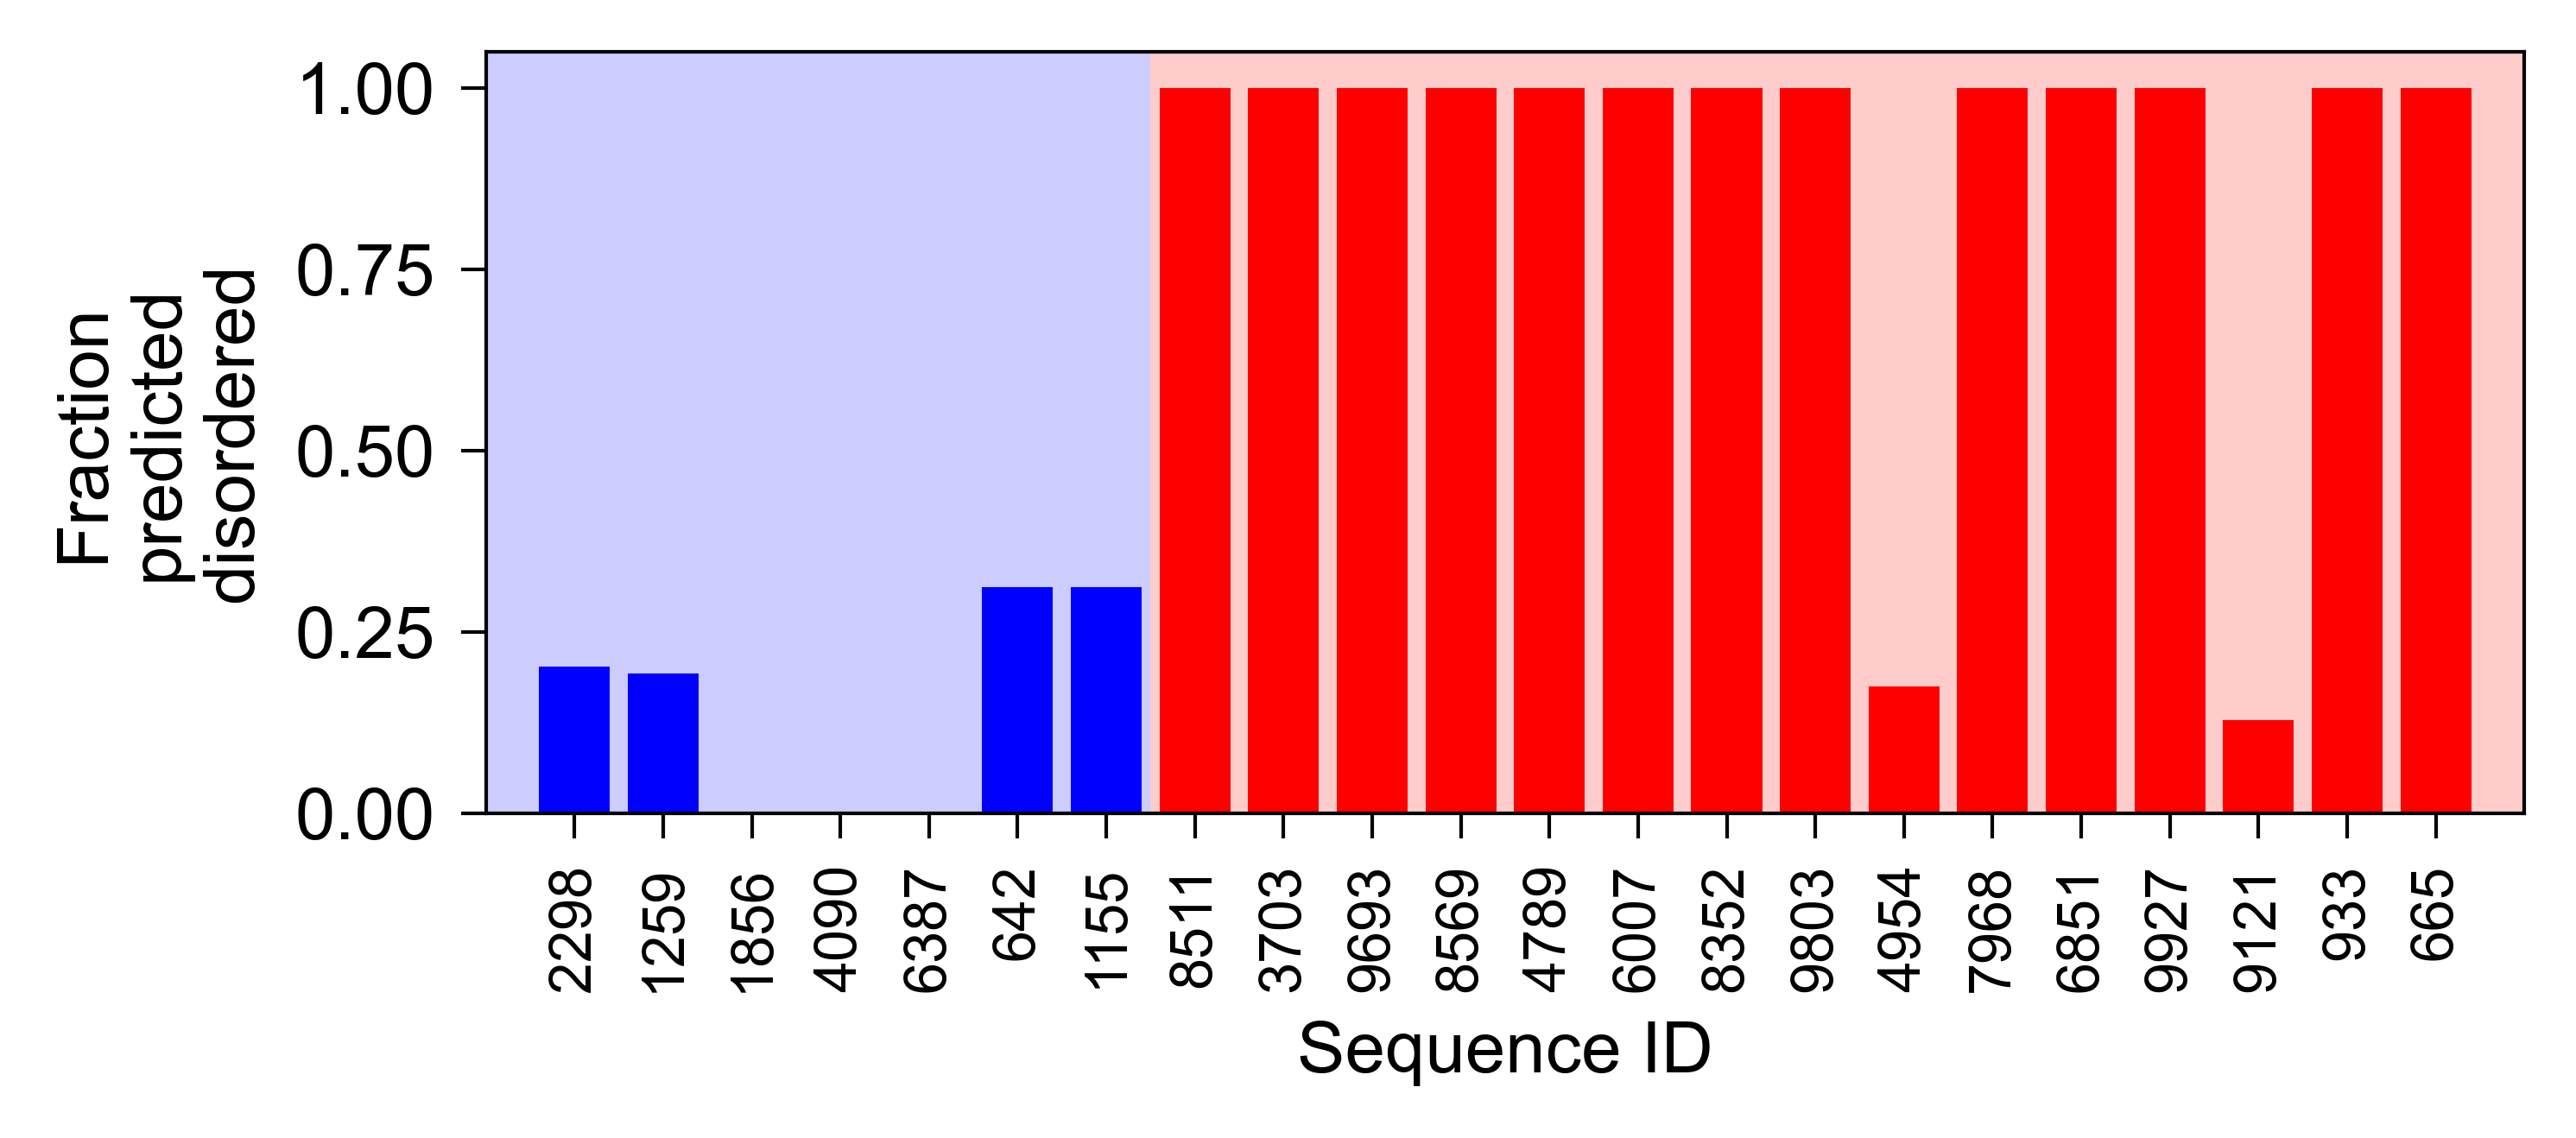

In [3]:
n_ord, n_dis = len(ordered), len(disordered)
fig, ax = plt.subplots(figsize=(5, 2.3), dpi=300)
ax.bar(np.arange(1, n_ord + 1), ordered, color=FOLDED_COLOR)
ax.bar(np.arange(n_ord + 1, n_ord + n_dis + 1), disordered, color=DISORDERED_COLOR)
ax.axvspan(0, n_ord + 0.5, color=FOLDED_COLOR, alpha=0.2, linewidth=0)
ax.axvspan(n_ord + 0.5, n_ord + n_dis + 1, color=DISORDERED_COLOR, alpha=0.2, linewidth=0)
ax.set_xticks(np.arange(1, n_ord + n_dis + 1), ordered_names + disordered_names, rotation=90, fontsize=8)
ax.set_xlim([0, n_ord + n_dis + 1])
ax.set_xlabel('Sequence ID')
ax.set_ylabel('Fraction\npredicted\ndisordered')
plt.tight_layout()
save_panel(fig, 'figure_S15E')